Chapter 7: Unsupervised Learning

Context:
Supervised learning (Chapters 5 and 6) predicts a target we already know. Often there is no target, only data, and we want to find its natural groups. Businesses do this to split customers into segments, such as low spenders and high spenders.

Problem:
Find the natural groups (clusters) in data without any labels, and decide which group each observation belongs to.

Solution:
Simulate dice rolls from a 6-sided and a 12-sided pair, model each with a bell curve, and classify each roll by which bell curve is higher. Then apply E-M clustering (Guess, Expectation, Maximization, Convergence) to two-dimensional data, and compare it with k-means clustering.

Tools:
random, NumPy, Matplotlib, SciPy (stats.norm, multivariate_normal), requests, ast, scikit-learn (KMeans)

Implementation:

[3, 3, 1, 6, 1, 4, 6, 1, 4, 4]


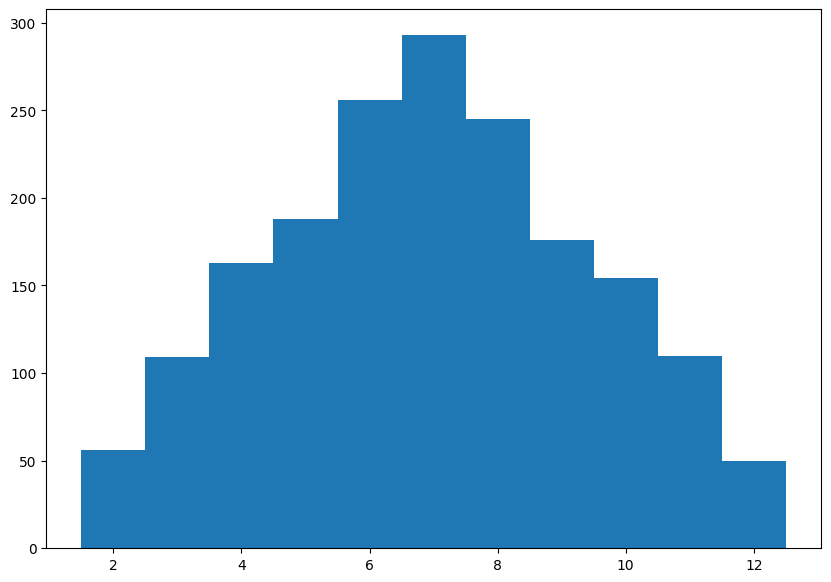

In [1]:
from random import choices,seed
numberofrolls=1800
seed(9)
dice1=choices([1,2,3,4,5,6], k=numberofrolls)
dice2=choices([1,2,3,4,5,6], k=numberofrolls)
print(dice1[0:10])

dicesum=[dice1[n]+dice2[n] for n in range(numberofrolls)]

from matplotlib import pyplot as plt
import numpy as np
fig, ax = plt.subplots(figsize =(10, 7))
ax.hist(dicesum,bins=[2,3,4,5,6,7,8,9,10,11,12,13],align='left')
plt.show()

In [2]:
def getcenter(allpoints):
    center=np.mean(allpoints)
    stdev=np.sqrt(np.cov(allpoints))
    return(center,stdev)

print(getcenter(dicesum))

(np.float64(6.9511111111111115), np.float64(2.468219092930105))


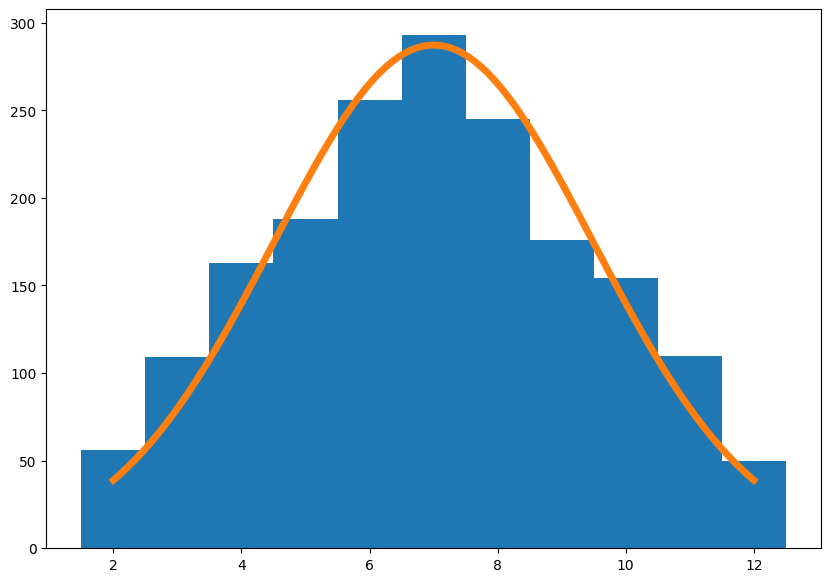

38.8734958894954
287.23844188903155
38.8734958894954


In [3]:
fig, ax = plt.subplots(figsize =(10, 7))
ax.hist(dicesum,bins=range(2,14),align='left')
import scipy.stats as stats
import math
mu=7
sigma=2.5
x = np.linspace(mu - 2*sigma, mu + 2*sigma, 100)*1
plt.plot(x, stats.norm.pdf(x, mu, sigma)*numberofrolls,linewidth=5)
plt.show()

print(stats.norm.pdf(2, mu, sigma)*numberofrolls)
print(stats.norm.pdf(7, mu, sigma)*numberofrolls)
print(stats.norm.pdf(12, mu, sigma)*numberofrolls)

A second kind of die: a pair of 12-sided dice numbered 4 to 15. Combining both sets of rolls gives a histogram with two peaks (bimodal), one cluster around 7 and one around 19.

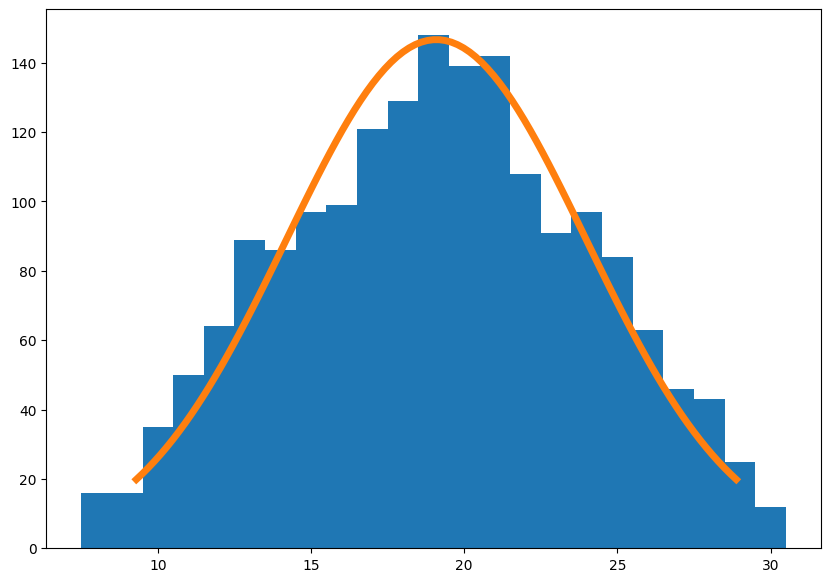

In [4]:
seed(913)
dice1=choices([4,5,6,7,8,9,10,11,12,13,14,15], k=numberofrolls)
dice2=choices([4,5,6,7,8,9,10,11,12,13,14,15], k=numberofrolls)
dicesum12=[dice1[n]+dice2[n] for n in range(numberofrolls)]
fig, ax = plt.subplots(figsize =(10, 7))
ax.hist(dicesum12,bins=range(8,32),align='left')
mu=np.mean(dicesum12)
sigma=np.std(dicesum12)
x = np.linspace(mu - 2*sigma, mu + 2*sigma, 100)*1
plt.plot(x, stats.norm.pdf(x, mu, sigma)*numberofrolls,linewidth=5)
plt.show()

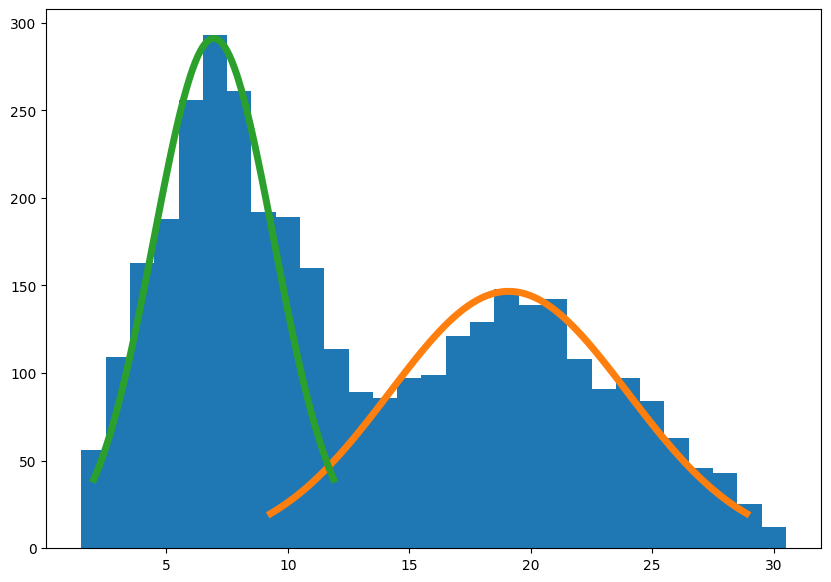

In [5]:
dicesumboth=dicesum+dicesum12
fig, ax = plt.subplots(figsize =(10, 7))
ax.hist(dicesumboth,bins=range(2,32),align='left')
mu=np.mean(dicesum12)
sigma=np.std(dicesum12)
x = np.linspace(mu - 2*sigma, mu + 2*sigma, 100)*1
plt.plot(x, stats.norm.pdf(x, mu, sigma)*numberofrolls,linewidth=5)
mu=np.mean(dicesum)
sigma=np.std(dicesum)
x = np.linspace(mu - 2*sigma, mu + 2*sigma, 100)*1
plt.plot(x, stats.norm.pdf(x, mu, sigma)*numberofrolls,linewidth=5)
plt.show()

Which dice pair rolled a given number? Compare the heights of the two bell curves at that value.

In [6]:
seed(494)
randomselection=choices(dicesumboth, k=1)
print(randomselection)

print(stats.norm.pdf(8, np.mean(dicesum), np.std(dicesum))*numberofrolls)
print(stats.norm.pdf(8, np.mean(dicesum12), np.std(dicesum12))*numberofrolls)
print(stats.norm.pdf(12, np.mean(dicesum), np.std(dicesum))*numberofrolls)
print(stats.norm.pdf(12, np.mean(dicesum12), np.std(dicesum12))*numberofrolls)

[12]
265.87855493973007
11.289203035758725
35.87586208537935
51.42993240324318


In [7]:
from scipy.stats import multivariate_normal
def classify(allpts,allmns,allvar):
    vars=[]
    for n in range(len(allmns)):
        vars.append(multivariate_normal(mean=allmns[n], cov=allvar[n]))
    classification=[]
    for point in allpts:
        this_classification=-1
        this_pdf=0
        for n in range(len(allmns)):
            if vars[n].pdf(point)>this_pdf:
                this_pdf=vars[n].pdf(point)
                this_classification=n+1
        classification.append(this_classification)
    return classification

allpoints = [2,8,12,15,25]
allmeans = [7, 19]
allvar = [np.cov(dicesum),np.cov(dicesum12)]
print(classify(allpoints,allmeans,allvar))

[1, 1, 2, 2, 2]


E-M clustering on two-dimensional data. Step 1, Guessing: start with poor guesses for the three cluster centers and covariances.

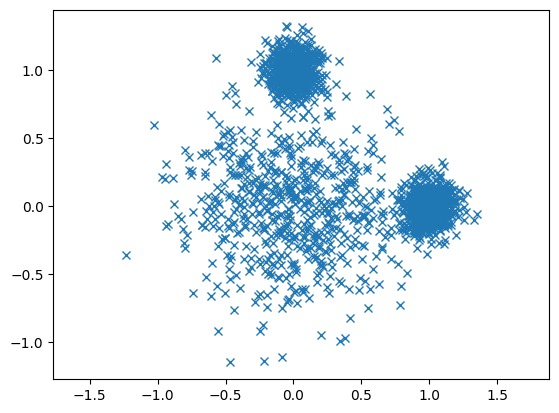

In [8]:
import ast
import requests
link = "https://bradfordtuckfield.com/emdata.txt"
f = requests.get(link)
allpoints = ast.literal_eval(f.text)

allxs=[point[0] for point in allpoints]
allys=[point[1] for point in allpoints]
plt.plot(allxs, allys, 'x')
plt.axis('equal')
plt.show()

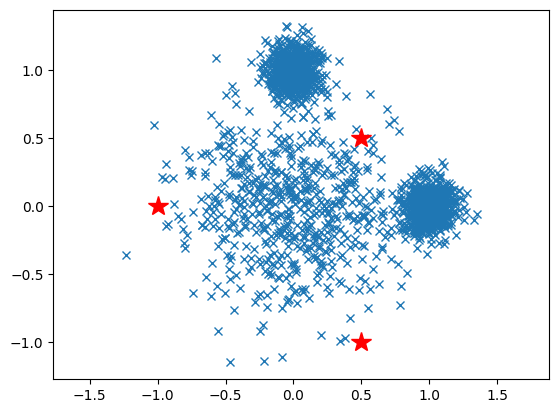

In [9]:
#initial guesses
mean1=[-1,0]
mean2=[0.5,-1]
mean3=[0.5,0.5]
allmeans=[mean1,mean2,mean3]

cov1=[[1,0],[0,1]]
cov2=[[1,0],[0,1]]
cov3=[[1,0],[0,1]]
allvar=[cov1,cov2,cov3]

plt.plot(allxs, allys, 'x')
plt.plot(mean1[0],mean1[1],'r*', markersize=15)
plt.plot(mean2[0],mean2[1],'r*', markersize=15)
plt.plot(mean3[0],mean3[1],'r*', markersize=15)
plt.axis('equal')
plt.show()

Step 2, Expectation: assign each point to the cluster whose bell curve is highest at that point.

[1, 1, 1, 1, 3, 1, 3, 3, 1, 3]


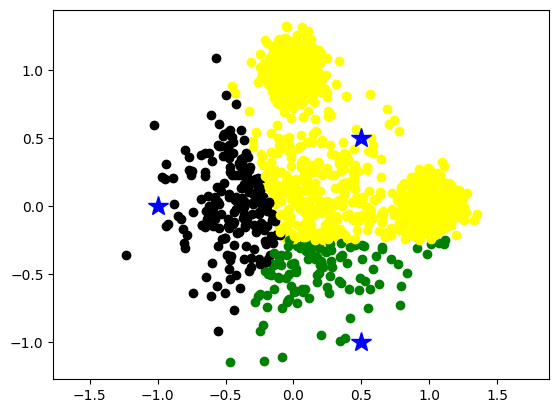

In [10]:
theclass=classify(allpoints,allmeans,allvar)
print(theclass[:10])

def makeplot(allpoints,theclass,allmeans):
    thecolors=['black']*len(allpoints)
    for idx in range(len(thecolors)):
        if theclass[idx]==2:
            thecolors[idx]='green'
        if theclass[idx]==3:
            thecolors[idx]='yellow'
    allxs=[point[0] for point in allpoints]
    allys=[point[1] for point in allpoints]
    for i in range(len(allpoints)):
        plt.scatter(allxs[i], allys[i],color=thecolors[i])
    for i in range(len(allmeans)):
        plt.plot(allmeans[i][0],allmeans[i][1],'b*', markersize=15)
    plt.axis('equal')
    plt.show()

makeplot(allpoints,theclass,allmeans)

Step 3, Maximization: recalculate each cluster's center and covariance from the points assigned to it.

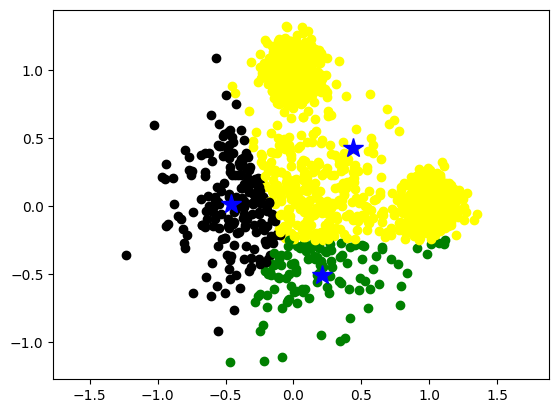

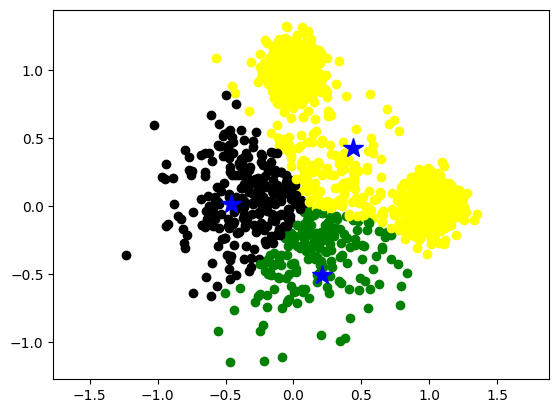

In [11]:
def getcenters(allpoints,theclass,k):
    centers=[]
    thevars=[]
    for n in range(k):
        pointsn=[allpoints[i] for i in range(0,len(allpoints)) if theclass[i]==(n+1)]
        xpointsn=[points[0] for points in pointsn]
        ypointsn=[points[1] for points in pointsn]
        xcenter=np.mean(xpointsn)
        ycenter=np.mean(ypointsn)
        centers.append([xcenter,ycenter])
        thevars.append(np.cov(xpointsn,ypointsn))
    return centers,thevars

allmeans,allvar=getcenters(allpoints,theclass,3)
makeplot(allpoints,theclass,allmeans)

theclass=classify(allpoints,allmeans,allvar)
makeplot(allpoints,theclass,allmeans)

Step 4, Convergence: repeat Expectation and Maximization until the clusters stop changing (100 rounds is more than enough here).

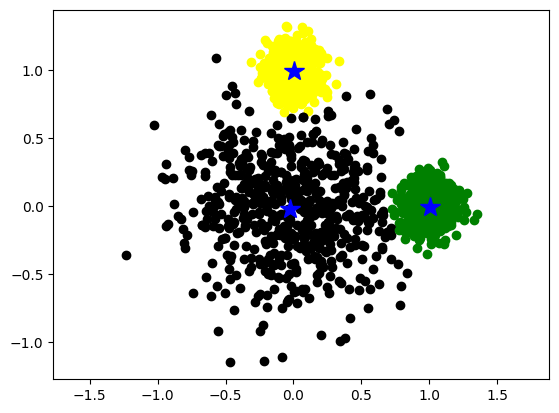

In [12]:
for n in range(0,100):
    theclass=classify(allpoints,allmeans,allvar)
    allmeans,allvar=getcenters(allpoints,theclass,3)

makeplot(allpoints,theclass,allmeans)

k-means clustering: a simpler method that assigns each point to the nearest center, using distance only and no covariance.

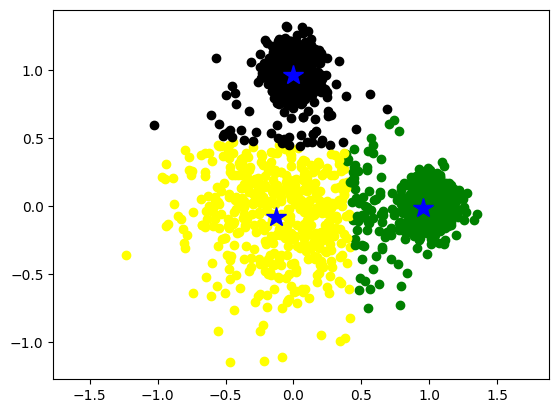

In [13]:
from sklearn.cluster import KMeans
kmeans = KMeans(init="random", n_clusters=3, n_init=10, max_iter=300, random_state=42)
kmeans.fit(allpoints)
newclass=[label+1 for label in kmeans.labels_]
makeplot(allpoints,newclass,kmeans.cluster_centers_)

Conclusion:
Unsupervised learning finds structure in data that has no labels. Modeling each dice pair with a bell curve let us classify rolls by which curve was higher, so 2 and 8 came from the 6-sided pair and 12, 15 and 25 from the 12-sided pair. E-M clustering repeated the Expectation and Maximization steps and moved from bad initial guesses to three sensible clusters: two dense ones and one spread-out one. k-means gave similar clusters, but because it uses distance only and assumes clusters of similar size, it handled the spread-out cluster less well. With no ground truth, we can't prove which result is correct, so clustering is best used for exploration and customer segmentation.